# C · Cooperation GAP

[Figure 3 index](../README.md#figure-3) · [Complete
assembly](figure3_assembly.ipynb#complete-figure-3).

Figure 3C plots the Cooperation GAP against the Social Rank GAP for
non-friends, mutual friends, and sender-declared one-sided friendships.
Solid curves use observed transfers; semi-transparent curves use
null-model-filtered transfers.

# Build the child and interval summaries

For each child and friendship group, the descriptive GAP is mean tokens
received minus mean tokens sent. Children are grouped into seven
equal-width intervals of their median Social Rank GAP. Each plotted
point averages the finite child-level GAPs in its interval. The code
below builds these summaries directly from the prepared dyad data, so
this page can be run after [Data and measures](01_data_and_measures.ipynb)
without executing either preceding figure page. The loading step
prepares missing inputs automatically.

In [ ]:
here::i_am("notebooks/main/07_figure3c_cooperation_gap.qmd")
library(tidyverse)
library(here)
source(here("code", "00_style.R"))

The data are reused if `analysis_dyads` and `analysis_students` are
already in R. Otherwise, this step loads their CSV files from
`data/generated/main/`, or builds them from the raw inputs on first use.

In [ ]:
source(here("code", "00_load_main_data.R"), local = TRUE)
dyads <- analysis_dyads

In [ ]:
main_data_status

dataset,rows,source
analysis_dyads,17804,Saved CSV files
analysis_students,859,Saved CSV files


The next chunks use `summary_by_child()` and `summary_by_bin()` to build
the auxiliary tables `children` and `binned` from `analysis_dyads`. They
contain the observed and filtered summaries inspected below.
`plot_coop_gap()` uses `binned` to draw the curves.

In [ ]:
# Panels B and C summarize transfers in two aggregation stages:
#
#   1. Summary by child. For each child (sender) and friendship group: her
#      mean tokens sent, her mean tokens received, her Cooperation GAP as the
#      difference between those two means (received - sent), and the median
#      Social Rank GAP of those partners. With observed transfers, panel C
#      equals the distance between the two mean curves of panel B.
#   2. Bins. The median rank gaps of the group are split into 7 intervals of
#      equal width ("round_gap"). The bins use all the children of the group,
#      so the observed and the filtered versions share the same bins.
#   3. Table of means by bin. Across the children of each bin: the mean and
#      SD of each measure, the position of the bin (mean of the children's
#      median gaps) and a 95% interval, mean +/- 1.96 * SD / sqrt(n), with n
#      the number of children in the bin.
#   4. The panels draw that table.
#
# Filtered version: a transfer dropped by the null-model filter is NA.
# Each direction keeps all of its retained transfers:
# the child's mean filtered tokens received minus her mean filtered tokens
# sent. (The filtered regressions, instead, use only pairs with both
# directions retained.) Children with nothing retained in one of the two
# directions have no filtered GAP; they stay in the total bin count n, and
# `n_with_value` counts finite child GAPs. The filtered sent, received, and GAP
# means can use different valid-child sets, so their bin-level difference
# need not equal the filtered GAP curve.

summary_by_child <- function(data, sent, received) {
  data %>%
    group_by(sender_id) %>%
    summarise(gap      = median(rank_gap),
              sent     = mean({{ sent }}, na.rm = TRUE),
              received = mean({{ received }}, na.rm = TRUE),
              .groups  = "drop") %>%
    mutate(dif_coop = received - sent)
}

summary_by_bin <- function(children, coef = 1.96, n_bins = 7) {
  children %>%
    mutate(round_gap = cut_interval(gap, n_bins, dig.lab = 1)) %>%
    group_by(round_gap) %>%
    summarise(median_gap    = mean(gap),     # position of the bin on the x axis
              n             = n(),
              n_with_value  = sum(is.finite(dif_coop)),
              mean_sent     = mean(sent, na.rm = TRUE),
              sd_sent       = sd(sent, na.rm = TRUE),
              mean_reci     = mean(received, na.rm = TRUE),
              sd_reci       = sd(received, na.rm = TRUE),
              mean_dif_coop = mean(dif_coop, na.rm = TRUE),
              sd_dif_coop   = sd(dif_coop, na.rm = TRUE),
              .groups = "drop") %>%
    mutate(se_sent     = coef * sd_sent / sqrt(n),
           se_reci     = coef * sd_reci / sqrt(n),
           se_dif_coop = coef * sd_dif_coop / sqrt(n))
}

rank_groups <- c("Non-friends", "Mutual", "Sender declares")

In [ ]:
# Step 1, for every friendship group, with observed and with filtered tokens
children <- map_dfr(rank_groups, function(this_group) {
  group_data <- dyads %>% filter(friendship == this_group)
  bind_rows(
    summary_by_child(group_data, tokens_sent, tokens_received) %>% mutate(version = "Observed"),
    summary_by_child(group_data, tokens_sent_filtered, tokens_received_filtered) %>% mutate(version = "Filtered")
  ) %>%
    mutate(group = this_group)
})

# a few children of the non-friends group, filtered tokens
children %>% filter(group == "Non-friends", version == "Filtered") %>% head()

In [ ]:
# Steps 2 and 3: the table of means by bin that the panels draw
binned <- children %>%
  group_by(group, version) %>%
  group_modify(~ summary_by_bin(.x)) %>%
  ungroup()

# Panel C, non-friends: Cooperation GAP by bin, observed and filtered
binned %>%
  filter(group == "Non-friends") %>%
  select(version, round_gap, median_gap, n, n_with_value, mean_dif_coop, se_dif_coop) %>%
  mutate(across(where(is.double), ~ round(.x, 2)))

# Observed and filtered support

With observed transfers, every child’s sent and received means use the
same partners. The mean child-level Cooperation GAP therefore equals the
difference between the two mean curves in [Figure
3B](06_figure3b_tokens_by_rank.ipynb).

With filtered transfers, each direction uses its own retained
allocations. A child may have a sent mean, a received mean, both, or
neither. `dif_coop` is finite only when both means exist, and the
plotted filtered GAP averages those finite child-level differences.
Consequently, the filtered GAP need not equal the difference between
separately averaged sent and received curves. This descriptive
construction also differs from the filtered regressions, which require
both transfers of each pair to be retained.

In [ ]:
children %>%
  filter(version == "Filtered") %>%
  group_by(group) %>%
  summarise(n_children = n(),
            n_valid_sent = sum(is.finite(sent)),
            n_valid_received = sum(is.finite(received)),
            n_valid_coop_gap = sum(is.finite(dif_coop)),
            .groups = "drop")

group,n_children,n_valid_sent,n_valid_received,n_valid_coop_gap
Mutual,654,507,511,410
Non-friends,859,827,854,823
Sender declares,655,444,427,311


For each interval, `n` counts all children and `n_with_value` counts
finite child-level GAPs. The displayed interval half-width `se_dif_coop`
is computed as $1.96\,SD/\sqrt{n}$ using the total interval count. The
plotting table exposes both counts so that support can be inspected
directly.

In [ ]:
binned %>%
  select(group, version, round_gap, median_gap, n, n_with_value, mean_dif_coop, se_dif_coop)

group,version,round_gap,median_gap,n,n_with_value,mean_dif_coop,se_dif_coop
Mutual,Filtered,"[-0.9,-0.7]",-0.8165002,7,5,-0.5333333,2.0182457
Mutual,Filtered,"(-0.7,-0.4]",-0.5124304,38,21,0.5000000,0.9774177
Mutual,Filtered,"(-0.4,-0.2]",-0.2488365,153,81,0.3888889,0.5320207
Mutual,Filtered,"(-0.2,0.1]",-0.0155174,271,180,-0.2629630,0.4316279
Mutual,Filtered,"(0.1,0.4]",0.2056146,135,91,0.3864469,0.6099633
Mutual,Filtered,"(0.4,0.6]",0.4694983,40,27,-0.0709877,0.6160997
Mutual,Filtered,"(0.6,0.9]",0.7168571,10,5,-0.7000000,3.7803111
Mutual,Observed,"[-0.9,-0.7]",-0.8165002,7,7,-0.7857143,0.7363876
Mutual,Observed,"(-0.7,-0.4]",-0.5124304,38,38,0.1710526,1.2732764
Mutual,Observed,"(-0.4,-0.2]",-0.2488365,153,153,-0.1307190,0.5942659


# Example: draw non-friends directly

Draw the observed and filtered curves directly from the non-friend rows,
using explicit `ggplot()` layers. The intervals are the same ones
reported in the plotting table above.

In [ ]:
# Draw the non-friend observed and filtered GAP curves without a plotting function.
non_friend_gap_bins <- binned %>%
  filter(group == "Non-friends", is.finite(mean_dif_coop))

gap_non_friends <- ggplot(non_friend_gap_bins,
       aes(x = median_gap, y = mean_dif_coop, alpha = version)) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey40") +
  geom_hline(yintercept = 0, linetype = "dashed", color = "grey40") +
  geom_line(color = color_non_friends, linewidth = 0.9) +
  geom_errorbar(aes(ymin = mean_dif_coop - se_dif_coop,
                    ymax = mean_dif_coop + se_dif_coop),
                color = color_non_friends, width = 0.04) +
  geom_point(color = color_non_friends, size = 2.8) +
  scale_alpha_manual(values = c(Observed = 1, Filtered = 0.4)) +
  annotate("text", x = c(-0.55, 0.55), y = -5.6, size = 2.3, fontface = "bold",
           label = c("Receiver higher rank", "Sender higher rank")) +
  annotate("text", x = 1.05, y = c(5.7, 4.9), hjust = 1, size = 2.5,
           fontface = "bold", color = color_non_friends, alpha = c(1, 0.4),
           label = c("Observed data", "Null-model filtered")) +
  scale_x_continuous(limits = c(-1.1, 1.1), breaks = seq(-1, 1, 0.5)) +
  scale_y_continuous(limits = c(-6, 6), breaks = seq(-7.5, 5, 2.5)) +
  labs(x = "Social Rank GAP", y = "Cooperation GAP\n[Received - Sent]") +
  theme_paper(base_size = 9)

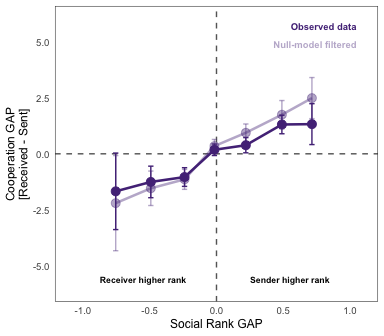

In [ ]:
gap_non_friends

# The reusable plotting function

The function below applies the same plotting instructions to each
relationship group. It also allows the vertical limits and the
emphasized curve to be specified.

In [ ]:
# Reuse the same specification, with optional emphasis and limits.
plot_coop_gap <- function(this_group, color, y_limits = c(-6, 6), main = "Observed",
                          short_labels = FALSE) {
  bins <- binned %>% filter(group == this_group, is.finite(mean_dif_coop))
  back <- setdiff(c("Observed", "Filtered"), main)
  curve_labels <- c(Observed = "Observed data", Filtered = "Null-model filtered")

  ggplot(bins, aes(x = median_gap, y = mean_dif_coop, alpha = version)) +
    geom_vline(xintercept = 0, linetype = "dashed", color = "grey40") +
    geom_hline(yintercept = 0, linetype = "dashed", color = "grey40") +
    geom_line(color = color, linewidth = 0.9) +
    geom_errorbar(aes(ymin = mean_dif_coop - se_dif_coop, ymax = mean_dif_coop + se_dif_coop),
                  color = color, width = 0.04) +
    geom_point(color = color, size = 2.8) +
    scale_alpha_manual(values = setNames(c(1, 0.4), c(main, back))) +
    annotate("text", x = c(-0.55, 0.55), y = y_limits[1] + 0.4, size = 2.3, fontface = "bold",
             label = c("Receiver higher rank", "Sender higher rank")) +
    {if (short_labels)
      annotate("text", x = c(0.42, 1.08), y = y_limits[1] + 1.4, hjust = 1, size = 2.2,
               fontface = "bold", color = color, alpha = c(1, 0.5), label = c(main, back))
     else
      annotate("text", x = 1.05, y = y_limits[2] - c(0.3, 1.1), hjust = 1, size = 2.5,
               fontface = "bold", color = color, alpha = c(1, 0.4),
               label = curve_labels[c(main, back)])} +
    scale_x_continuous(limits = c(-1.1, 1.1), breaks = seq(-1, 1, 0.5)) +
    scale_y_continuous(limits = y_limits, breaks = seq(-7.5, 5, 2.5)) +
    labs(x = "Social Rank GAP", y = "Cooperation GAP\n[Received - Sent]") +
    theme_paper(base_size = 9)
}

# Mutual friends

In [ ]:
gap_mutual <- plot_coop_gap("Mutual", color_mutual)

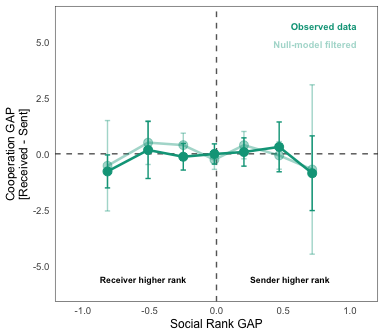

In [ ]:
gap_mutual

# Sender-declared one-sided friendships

In [ ]:
gap_asymmetric <- plot_coop_gap("Sender declares", color_asymmetric, c(-8.5, 6))

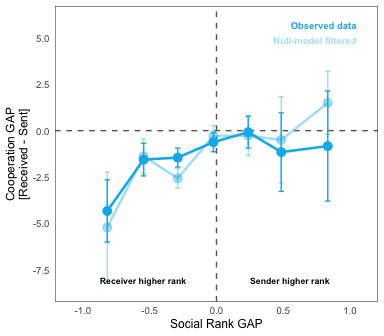

In [ ]:
gap_asymmetric

# Complete Figure 3

[Open the complete assembly](figure3_assembly.ipynb#complete-figure-3) to
see all nine panels, the A–C labels, and the three colored relationship
headers.

The [Figure 3 summary
dictionary](../../data/figure3_codebook.md#figure-3-summary-tables) records the
definitions and units of every Figure 3 summary column.

# Session information

In [ ]:
sessionInfo()
## R version 4.3.2 (2023-10-31)
## Platform: aarch64-apple-darwin20 (64-bit)
## Running under: macOS 26.7.1
## 
## Matrix products: default
## BLAS:   /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRblas.0.dylib 
## LAPACK: /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRlapack.dylib;  LAPACK version 3.11.0
## 
## locale:
## [1] C.UTF-8/C.UTF-8/C.UTF-8/C/C.UTF-8/C.UTF-8
## 
## time zone: America/Santiago
## tzcode source: internal
## 
## attached base packages:
## [1] stats     graphics  grDevices utils     datasets  methods   base     
## 
## other attached packages:
##  [1] lubridate_1.9.4 forcats_1.0.0   stringr_1.5.1   dplyr_1.1.4    
##  [5] purrr_1.0.4     readr_2.1.5     tidyr_1.3.1     tibble_3.2.1   
##  [9] ggplot2_3.5.2   tidyverse_2.0.0 here_1.0.1     
## 
## loaded via a namespace (and not attached):
##  [1] bit_4.6.0         gtable_0.3.6      jsonlite_2.0.0    crayon_1.5.3     
##  [5] compiler_4.3.2    tidyselect_1.2.1  parallel_4.3.2    scales_1.3.0     
##  [9] yaml_2.3.10       fastmap_1.2.0     R6_2.6.1          generics_0.1.3   
## [13] knitr_1.50        munsell_0.5.1     rprojroot_2.0.4   pillar_1.10.2    
## [17] tzdb_0.5.0        rlang_1.1.6       stringi_1.8.7     xfun_0.52        
## [21] bit64_4.6.0-1     timechange_0.3.0  cli_3.6.4         withr_3.0.2      
## [25] magrittr_2.0.3    digest_0.6.37     grid_4.3.2        vroom_1.6.5      
## [29] hms_1.1.3         lifecycle_1.0.4   vctrs_0.6.5       evaluate_1.0.3   
## [33] glue_1.8.0        farver_2.1.2      colorspace_2.1-1  rmarkdown_2.29   
## [37] tools_4.3.2       pkgconfig_2.0.3   htmltools_0.5.8.1

[Continue to the complete Figure 3 assembly](figure3_assembly.ipynb).